<a href="https://colab.research.google.com/github/bfzeigler/svd-image-compression/blob/main/notebooks/01_image_as_matrix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
print("hello from Colab")

hello from Colab


# Milestone 1: Images as Matrices

Names: Bianca Zeigler

This notebook explores how images can be represented as matrices
and how matrix rank relates to image patterns.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

## Part A: A grayscale photograph is a matrix

Shape: (512, 512)
Data type: uint8
Smallest entry: 0
Largest entry: 255
Top-left 3 x 3 block:
 [[200 200 200]
 [200 199 199]
 [199 199 199]]


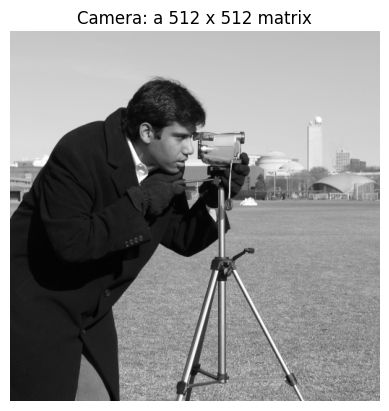

In [4]:
A = data.camera()

print("Shape:", A.shape)
print("Data type:", A.dtype)
print("Smallest entry:", A.min())
print("Largest entry:", A.max())
print("Top-left 3 x 3 block:\n", A[:3, :3])

plt.imshow(A, cmap="gray", vmin=0, vmax=255)
plt.title("Camera: a 512 x 512 matrix")
plt.axis("off")
plt.show()

This is a image with 512 rows and 512 columns where each matrix represents a pixel's brighness. A value of 0 is black and a value of 255 is white and uint8 stores whole numbers from 0 to 255.

## Part B: Color images

Color image shape: (512, 512, 3)


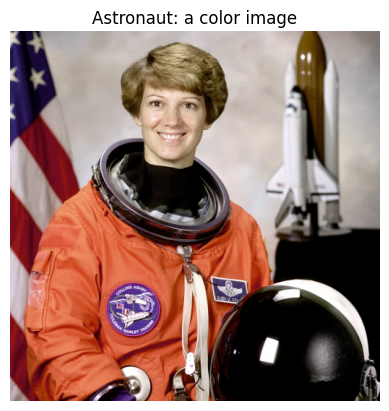

Red channel shape: (512, 512)
Green channel shape: (512, 512)
Blue channel shape: (512, 512)


In [5]:
C = data.astronaut()

print("Color image shape:", C.shape)

plt.imshow(C)
plt.title("Astronaut: a color image")
plt.axis("off")
plt.show()

R = C[:, :, 0]
G = C[:, :, 1]
B = C[:, :, 2]

print("Red channel shape:", R.shape)
print("Green channel shape:", G.shape)
print("Blue channel shape:", B.shape)

This color image contains three different brightness matrices. There is one matrix for red, one matrix for blue and one matrix for green.

## Part C: The uint8 trap

In [6]:
x = np.array([200], dtype=np.uint8)
y = np.array([100], dtype=np.uint8)

print("uint8 200 + 100 =", x + y)
print("float 200 + 100 =", x.astype(float) + y.astype(float))

uint8 200 + 100 = [44]
float 200 + 100 = [300.]


Since uint8 cannot store 300, the results wrap around to 300 - 256 = 44. The values are converted to floating point before adding in order to avoid this problem.

## Part D: Tiny images and matrix rank

In [7]:
cross = np.array([
    [0, 1, 1, 0],
    [1, 1, 1, 1],
    [1, 1, 1, 1],
    [0, 1, 1, 0]
])

gradient = np.array([
    [i + j for j in range(4)]
    for i in range(4)
])

checker = np.array([
    [(i + j + 1) % 2 for j in range(4)]
    for i in range(4)
])

print("Cross rank =", np.linalg.matrix_rank(cross))
print("Gradient rank =", np.linalg.matrix_rank(gradient))
print("Checkerboard rank =", np.linalg.matrix_rank(checker))

Cross rank = 2
Gradient rank = 2
Checkerboard rank = 2


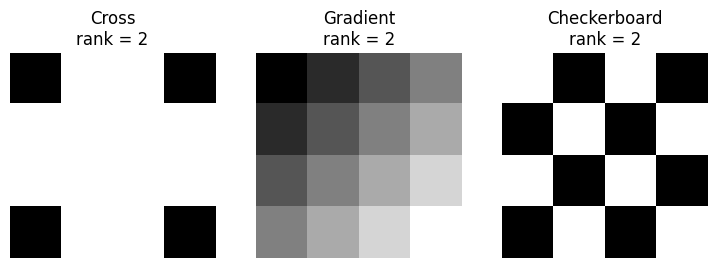

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3))

images = [
    ("Cross", cross),
    ("Gradient", gradient),
    ("Checkerboard", checker)
]

for ax, (name, M) in zip(axes, images):
    ax.imshow(M, cmap="gray", vmin=0, vmax=M.max())
    ax.set_title(f"{name}\nrank = {np.linalg.matrix_rank(M)}")
    ax.axis("off")

plt.show()

The rank measures the number of indepenedent row or column patterns. An image that looks like it has a lot going on can maintain a low rank when its patterns are repeated.

## A rank-1 image

[[1 1 1 1]
 [0 0 0 0]
 [1 1 1 1]
 [0 0 0 0]]
Rank = 1


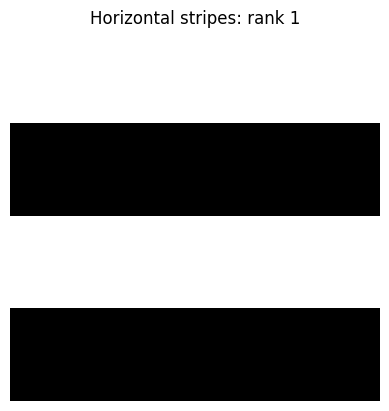

In [9]:
u = np.array([1, 0, 1, 0])
v = np.array([1, 1, 1, 1])

stripes = np.outer(u, v)

print(stripes)
print("Rank =", np.linalg.matrix_rank(stripes))

plt.imshow(stripes, cmap="gray", vmin=0, vmax=1)
plt.title("Horizontal stripes: rank 1")
plt.axis("off")
plt.show()

Since every row is a multple of [1,1,1,1] there is only one independent row pattern.

## Part E: My own photograph

In [10]:
from google.colab import files
from PIL import Image

uploaded = files.upload()

Saving IMG_6953.jpeg to IMG_6953.jpeg


Shape: (600, 800)
Data type: uint8


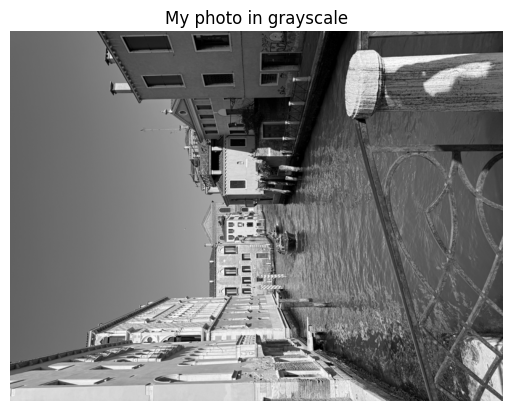

In [11]:
name = list(uploaded)[0]

img = Image.open(name).convert("L")
img.thumbnail((800, 800))

P = np.array(img)

print("Shape:", P.shape)
print("Data type:", P.dtype)

plt.imshow(P, cmap="gray", vmin=0, vmax=255)
plt.title("My photo in grayscale")
plt.axis("off")
plt.show()

.convert("L") takes the photo I uploaded and converts it to grayscale
.thumbnail((800, 800)) then limits the dimensions of the photo while still maintaining its proportions. Then, np.array(img) turns it into a matrix.

## Practice Exercises

Exercise #1:

18 - this pixel value would a very very dark gray that is very close to black.
127 - this would be a medium gray that is halfway between black and white.
245 - this would be a very light gray that is very close to white

Exercise #2

An image with the shape (600, 900, 3) would have 600 rows, 900 columns and 3 color channels.
There are 1,620,000 numbers used to store the uncompressed image array (600 * 900 * 3) = 1,620,000

Exercise #3


In [12]:
print(A[:5, :5])

[[200 200 200 200 199]
 [200 199 199 200 199]
 [199 199 199 200 200]
 [200 200 199 199 199]
 [200 200 200 200 199]]


The first :5 selects the first 5 rows and the second :5 selects the first 5 columns.

Exercise #4

In [14]:
a = np.array([250], dtype=np.uint8)
b = np.array([20], dtype=np.uint8)

print("uint8 result:", a + b)

uint8 result: [14]


270 - 256 = 14. Whereas when we use floating point arithmetic, the correct sum will be preserved.

In [15]:
a = np.array([250], dtype=np.uint8)
b = np.array([20], dtype=np.uint8)

print("float result:", a.astype(float) + b.astype(float))

float result: [270.]


Exercise #5

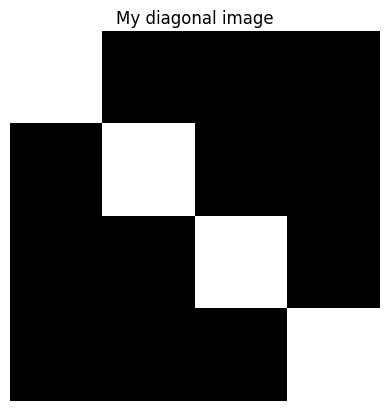

In [16]:
my_image = np.array([
    [1, 0, 0, 0],
    [0, 1, 0, 0],
    [0, 0, 1, 0],
    [0, 0, 0, 1]
])

plt.imshow(my_image, cmap="gray", vmin=0, vmax=1)
plt.title("My diagonal image")
plt.axis("off")
plt.show()

I predict that the rank will be 4 because all the rows are independent.

In [17]:
print("Calculated rank:", np.linalg.matrix_rank(my_image))

Calculated rank: 4


My prediction was correct

Exercise #6

[[0 1 0 1]
 [0 1 0 1]
 [0 1 0 1]
 [0 1 0 1]]
Rank: 1


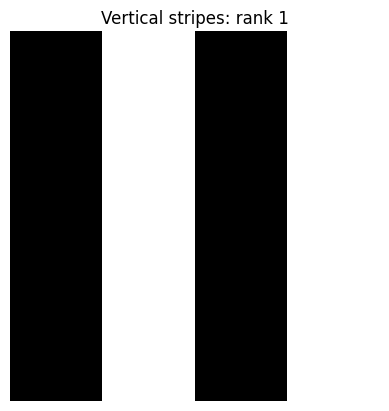

In [18]:
u_new = np.array([1, 1, 1, 1])
v_new = np.array([0, 1, 0, 1])

my_rank1 = np.outer(u_new, v_new)

print(my_rank1)
print("Rank:", np.linalg.matrix_rank(my_rank1))

plt.imshow(my_rank1, cmap="gray", vmin=0, vmax=1)
plt.title("Vertical stripes: rank 1")
plt.axis("off")
plt.show()

In this exercise, every row eqauls [0,1,0,1]. And since all rows are multiples of the same nonzero row, the rank is equal to 1.